# Pneumonia Detection from Chest X-Rays: Reproducing the Baseline (Milestone 2)

**Topic:** Pneumonia (chest X-ray), Kermany CXR dataset.

**Base paper:** D. S. Kermany *et al.*, "Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning", *Cell* 172(5), 2018. DOI: [10.1016/j.cell.2018.02.010](https://doi.org/10.1016/j.cell.2018.02.010)

**Public data + code:** [Mendeley Data, rscbjbr9sj v2](https://data.mendeley.com/datasets/rscbjbr9sj/2) (`ChestXRay2017.zip`, `code2017.zip`).

**Method of the paper (transfer learning):**
1. Take an **InceptionV3** network pre-trained on ImageNet.
2. **Freeze** all of it and use it as a fixed feature extractor: every X-ray becomes a 2048-number vector (the "bottleneck").
3. Train **only a new final layer** (2048 → 2 classes, softmax) to tell NORMAL from PNEUMONIA.

**Paper's reported result (pneumonia vs. normal, 624-image test set):**

| Metric | Paper |
|---|---|
| Accuracy | 92.8 % |
| Sensitivity (recall for pneumonia) | 93.2 % |
| Specificity | 90.1 % |
| ROC AUC | 96.8 % |

> Note: check these four values against Figure 6 of the Cell paper before final submission. The 92.8 % accuracy is cited consistently in later work.

Training settings below are copied from the authors' released code (`retrain.py`, `net/train.py`).

In [1]:
import os, json, random, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
DATA_DIR = "data/chest_xray"
os.makedirs("results", exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(0)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

PyTorch 2.15.0 | torchvision 0.29.2 | device: mps


## 1. Dataset
Pediatric chest X-rays (children aged 1-5, Guangzhou Women and Children's Medical Center), labelled NORMAL or PNEUMONIA.
The official split is used unchanged: `train/` and `test/`.

The training set is **imbalanced**: about 3 pneumonia images for every normal one.

In [2]:
# Same preprocessing as the paper's code: resize straight to 299x299 (InceptionV3 input size).
# X-rays are grayscale, so we repeat the channel 3 times for the ImageNet network.
tfm = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
train_ds = datasets.ImageFolder(f"{DATA_DIR}/train", transform=tfm)
test_ds  = datasets.ImageFolder(f"{DATA_DIR}/test",  transform=tfm)
CLASSES = train_ds.classes                     # ['NORMAL', 'PNEUMONIA'] -> PNEUMONIA = 1 = positive class
for name, ds in [("train", train_ds), ("test", test_ds)]:
    counts = np.bincount(ds.targets)
    print(f"{name:5s}: {len(ds):5d} images  " + "  ".join(f"{c}={n}" for c, n in zip(CLASSES, counts)))

train:  5232 images  NORMAL=1349  PNEUMONIA=3883
test :   624 images  NORMAL=234  PNEUMONIA=390


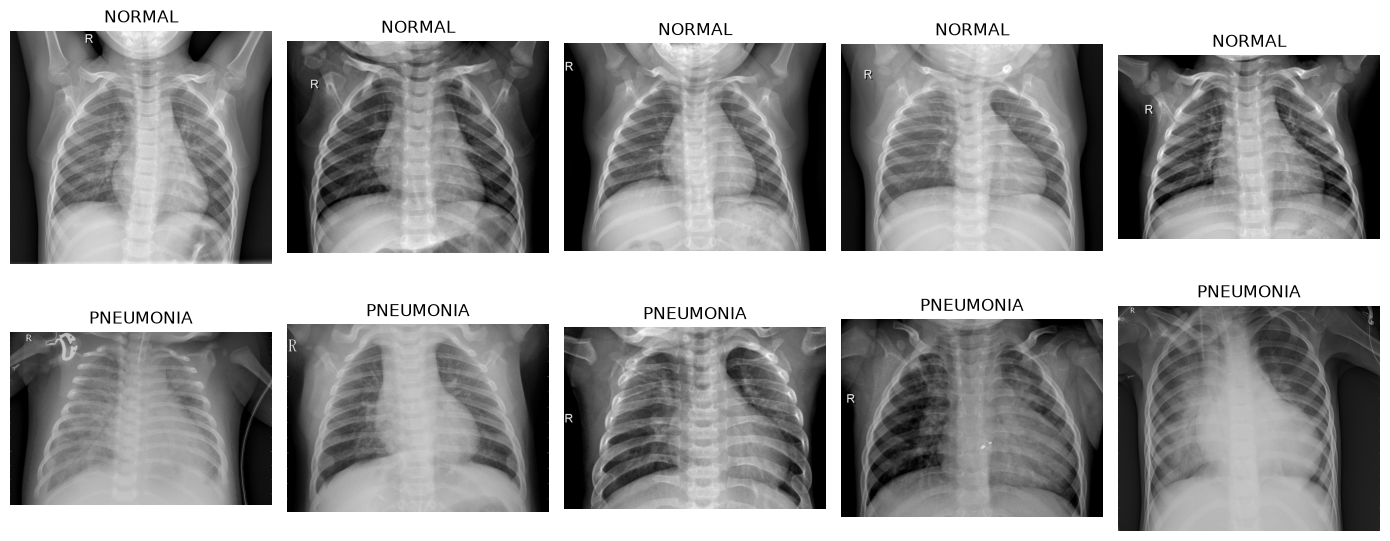

In [3]:
# A few example images
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate(range(2)):
    idx = [i for i, t in enumerate(train_ds.targets) if t == cls][:5]
    for ax, i in zip(axes[row], idx):
        img = plt.imread(train_ds.samples[i][0])
        ax.imshow(img, cmap="gray"); ax.set_title(CLASSES[cls]); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Frozen InceptionV3 feature extractor
We use torchvision's ImageNet-pretrained InceptionV3. Replacing its last layer (`fc`) with "identity" makes it output the 2048-number bottleneck vector. The network is frozen, so features are computed **once** and cached, exactly like the paper's code (`store_bottlenecks`).

In [4]:
backbone = torchvision.models.inception_v3(weights="IMAGENET1K_V1")
backbone.fc = nn.Identity()
backbone = backbone.eval().to(device)
for p in backbone.parameters():
    p.requires_grad = False

@torch.no_grad()
def extract(ds, cache):
    if os.path.exists(cache):
        return torch.load(cache)
    loader = torch.utils.data.DataLoader(ds, batch_size=64, num_workers=4)
    feats, labels, t0 = [], [], time.time()
    for x, y in loader:
        feats.append(backbone(x.to(device)).cpu()); labels.append(y)
    out = (torch.cat(feats), torch.cat(labels))
    torch.save(out, cache)
    print(f"extracted {len(out[0])} features in {time.time() - t0:.0f}s")
    return out

f_train, y_train = extract(train_ds, "results/feats_train.pt")
f_test,  y_test  = extract(test_ds,  "results/feats_test.pt")
print("train features:", tuple(f_train.shape), " test features:", tuple(f_test.shape))

train features: (5232, 2048)  test features: (624, 2048)


## 3. Train the final layer (paper's settings)
| Setting | Authors' code |
|---|---|
| New layer | Linear 2048 → 2, weights ~ N(0, 0.001), softmax + cross-entropy |
| Optimizer | Adam, learning rate 0.001 |
| Batch | 256 bottlenecks sampled at random each step |
| Training steps | 4000 |

The authors' code needs a separate `val/` folder for monitoring. We hold out a random 10 % of `train/` for that. The test set is used **only once**, at the end.

In [5]:
STEPS, BATCH, LR = 4000, 256, 1e-3

def split_train_val(seed, val_frac=0.1):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(f_train), generator=g)
    n_val = int(val_frac * len(f_train))
    return perm[n_val:], perm[:n_val]

def train_head(seed, log=False):
    set_seed(seed)
    tr, va = split_train_val(seed)
    Xtr, Ytr = f_train[tr].to(device), y_train[tr].to(device)
    Xva, Yva = f_train[va].to(device), y_train[va].to(device)
    head = nn.Linear(2048, 2).to(device)
    nn.init.normal_(head.weight, std=0.001); nn.init.zeros_(head.bias)
    opt = torch.optim.Adam(head.parameters(), lr=LR)
    hist = {"step": [], "train_acc": [], "val_acc": []}
    for step in range(1, STEPS + 1):
        idx = torch.randint(0, len(Xtr), (BATCH,), device=device)     # random batch, like the paper's code
        loss = F.cross_entropy(head(Xtr[idx]), Ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 100 == 0 or step == STEPS:
            with torch.no_grad():
                hist["step"].append(step)
                hist["train_acc"].append((head(Xtr).argmax(1) == Ytr).float().mean().item() * 100)
                hist["val_acc"].append((head(Xva).argmax(1) == Yva).float().mean().item() * 100)
            if log and step % 1000 == 0:
                print(f"step {step:4d}  loss {loss.item():.4f}  train acc {hist['train_acc'][-1]:.2f}%  val acc {hist['val_acc'][-1]:.2f}%")
    return head, hist

@torch.no_grad()
def test_metrics(head):
    prob = F.softmax(head(f_test.to(device)), 1)[:, 1].cpu().numpy()   # P(pneumonia)
    y = y_test.numpy(); pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"accuracy": 100 * (tp + tn) / len(y),
            "sensitivity": 100 * tp / (tp + fn),       # recall on PNEUMONIA
            "specificity": 100 * tn / (tn + fp),       # recall on NORMAL
            "precision": 100 * tp / (tp + fp),
            "auc": 100 * roc_auc_score(y, prob),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}, prob

head, hist = train_head(seed=0, log=True)

step 1000  loss 0.0655  train acc 97.94%  val acc 97.71%


step 2000  loss 0.0526  train acc 98.87%  val acc 98.47%


step 3000  loss 0.0264  train acc 99.45%  val acc 98.47%


step 4000  loss 0.0238  train acc 99.68%  val acc 98.66%


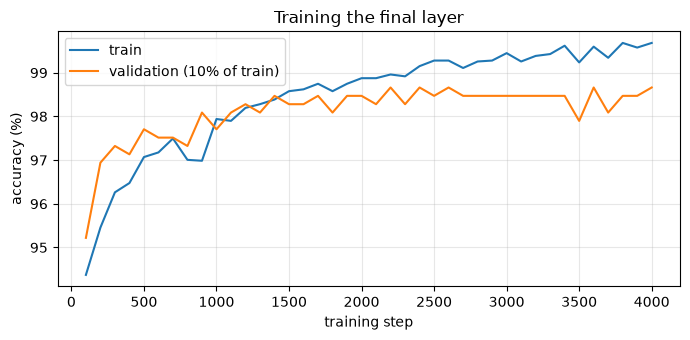

In [6]:
plt.figure(figsize=(7, 3.5))
plt.plot(hist["step"], hist["train_acc"], label="train"); plt.plot(hist["step"], hist["val_acc"], label="validation (10% of train)")
plt.xlabel("training step"); plt.ylabel("accuracy (%)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Training the final layer"); plt.tight_layout(); plt.savefig("results/training_curve.png", dpi=150); plt.show()

## 4. Test-set results vs. paper
Since only the last layer is trained, one run takes seconds. We repeat it with **5 random seeds** and report mean ± std so the comparison does not depend on one lucky run.

In [7]:
PAPER = {"accuracy": 92.8, "sensitivity": 93.2, "specificity": 90.1, "auc": 96.8}
SEEDS = [0, 1, 2, 3, 4]
runs = []
for s in SEEDS:
    h, _ = train_head(s)
    m, p = test_metrics(h)
    runs.append(m)
    if s == 0:
        head0, prob0, m0 = h, p, m

keys = ["accuracy", "sensitivity", "specificity", "precision", "auc"]
print(f"{'Metric':<13}{'Paper':>8}{'Ours (mean ± std, 5 seeds)':>30}")
for k in keys:
    vals = np.array([r[k] for r in runs])
    paper = f"{PAPER[k]:.1f}" if k in PAPER else "-"
    print(f"{k:<13}{paper:>8}{vals.mean():>21.2f} ± {vals.std():.2f}")
json.dump({"paper": PAPER, "runs": runs}, open("results/baseline_metrics.json", "w"), indent=2)

Metric          Paper    Ours (mean ± std, 5 seeds)
accuracy         92.8                80.13 ± 0.74
sensitivity      93.2                98.41 ± 0.30
specificity      90.1                49.66 ± 1.94
precision           -                76.52 ± 0.69
auc              96.8                92.89 ± 0.24


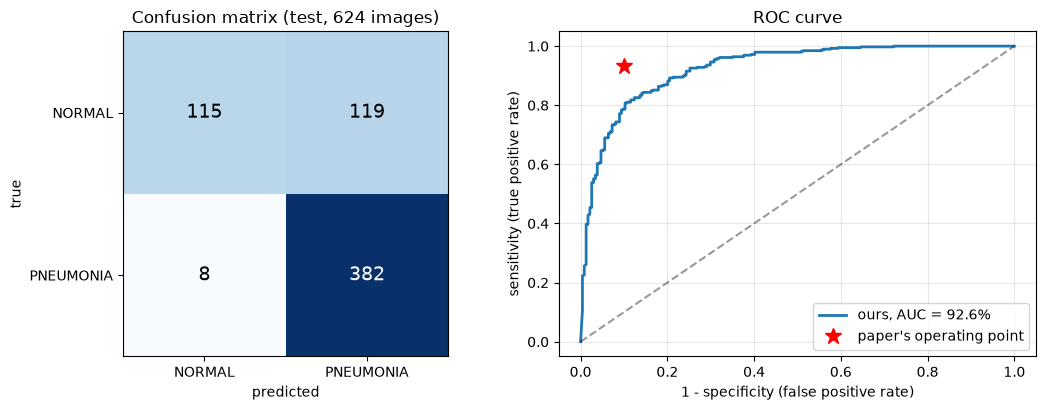

In [8]:
# Confusion matrix and ROC curve (seed 0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
cm = np.array([[m0["tn"], m0["fp"]], [m0["fn"], m0["tp"]]])
a1.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
a1.set_xticks([0, 1], CLASSES); a1.set_yticks([0, 1], CLASSES)
a1.set_xlabel("predicted"); a1.set_ylabel("true"); a1.set_title("Confusion matrix (test, 624 images)")

fpr, tpr, _ = roc_curve(y_test.numpy(), prob0)
a2.plot(fpr, tpr, lw=2, label=f"ours, AUC = {m0['auc']:.1f}%")
a2.plot(1 - PAPER["specificity"] / 100, PAPER["sensitivity"] / 100, "r*", ms=12, label="paper's operating point")
a2.plot([0, 1], [0, 1], "k--", alpha=0.4)
a2.set_xlabel("1 - specificity (false positive rate)"); a2.set_ylabel("sensitivity (true positive rate)")
a2.set_title("ROC curve"); a2.legend(loc="lower right"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/confusion_roc.png", dpi=150); plt.show()

127 of 624 test images wrong: 119 NORMAL called PNEUMONIA (false positives), 8 PNEUMONIA called NORMAL (false negatives)


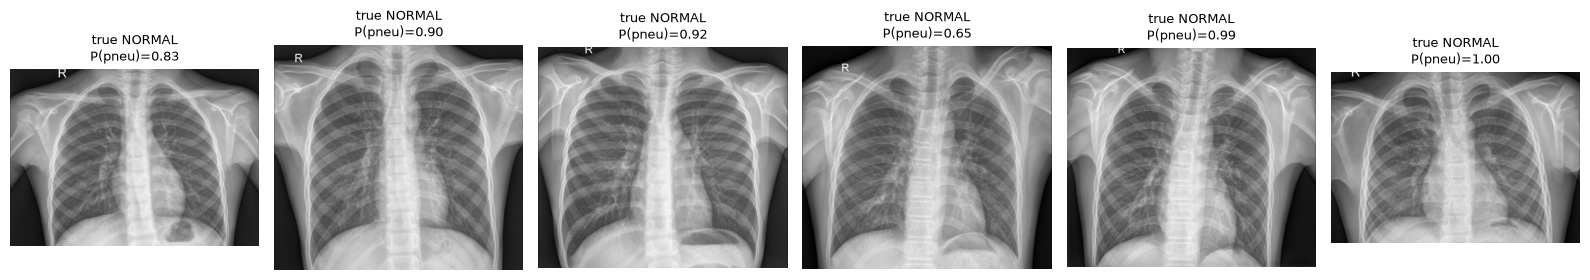

In [9]:
# Where does the baseline fail? A few misclassified test images (seed 0)
pred0 = (prob0 >= 0.5).astype(int); yt = y_test.numpy()
wrong = np.where(pred0 != yt)[0]
print(f"{len(wrong)} of {len(yt)} test images wrong: "
      f"{int(((pred0 == 1) & (yt == 0)).sum())} NORMAL called PNEUMONIA (false positives), "
      f"{int(((pred0 == 0) & (yt == 1)).sum())} PNEUMONIA called NORMAL (false negatives)")
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, i in zip(axes, wrong[:6]):
    ax.imshow(plt.imread(test_ds.samples[i][0]), cmap="gray"); ax.axis("off")
    ax.set_title(f"true {CLASSES[yt[i]]}\nP(pneu)={prob0[i]:.2f}", fontsize=9)
plt.tight_layout(); plt.savefig("results/failures.png", dpi=150); plt.show()

In [10]:
# Validation (same distribution as train) vs test: is there a train/test shift?
_, va = split_train_val(0)
val_acc = (head0(f_train[va].to(device)).argmax(1).cpu() == y_train[va]).float().mean().item() * 100
print(f"validation accuracy (held-out 10% of train/): {val_acc:.2f}%   vs   test accuracy: {m0['accuracy']:.2f}%")

# The 0.5 threshold is only one point on the ROC curve. Compare with the paper at the SAME sensitivity:
fpr, tpr, thr = roc_curve(y_test.numpy(), prob0)
i = np.argmax(tpr >= PAPER["sensitivity"] / 100)
print(f"at sensitivity {tpr[i] * 100:.1f}% (paper: 93.2%) our specificity is {(1 - fpr[i]) * 100:.1f}% "
      f"(paper: 90.1%), threshold P(pneumonia) >= {thr[i]:.3f}")

validation accuracy (held-out 10% of train/): 98.66%   vs   test accuracy: 79.65%
at sensitivity 93.6% (paper: 93.2%) our specificity is 70.9% (paper: 90.1%), threshold P(pneumonia) >= 0.945


## 5. Summary
- **Method reproduced:** frozen ImageNet InceptionV3, plus a new softmax layer trained with Adam (lr 0.001, batch 256, 4000 steps), on the official Kermany train/test split (5232 train / 624 test, same counts as the paper).
- **Result:** our **AUC is about 93 % vs. 96.8 %** in the paper, and our **sensitivity is higher** (about 98 % vs. 93.2 %). But **specificity is much lower** (about 50 % vs. 90.1 %), so accuracy is about 80 % vs. 92.8 %. The pipeline runs end-to-end and the ranking quality (AUC) is within about 4 points. The accuracy gap is mostly the decision threshold: the model calls too many normal X-rays "pneumonia".
- **Why the gap? (likely causes)**
  1. **Train/test shift:** validation accuracy on held-out *training* images is about 98-99 %, but test accuracy is about 80 %. The test images differ from the training images, and later work on this dataset reports the same effect.
  2. **Class imbalance (3:1 pneumonia:normal):** this pushes the 0.5 threshold toward "pneumonia". At the paper's sensitivity, our specificity is higher than at 0.5 (see the cell above).
  3. **Implementation differences:** torchvision InceptionV3 weights instead of the 2015 TensorFlow graph; PIL resizing instead of TensorFlow's bilinear resize; our own 10 % validation split. The paper also does not state which threshold or checkpoint it reported.
- **Weakness found (input to Milestone 3):** almost all errors are **NORMAL images called PNEUMONIA**, so specificity is the weak metric. The features were never adapted to X-rays, which motivates our hypothesis (fine-tune the top Inception blocks).

*Research exercise only; no clinical claims.*